# 7. El modelo original: aditivo penalizado por rondas

En el capítulo 5 evaluamos el EBM de la librería `interpret`. Como se obtiene con una sola línea de importación, no cumple la condición de implementación propia, y por eso lo tratamos allí como candidato interpretable. Este capítulo presenta el modelo que programamos nosotros, solo con numpy y pandas, y que llamamos **aditivo penalizado por rondas** (clase `AditivoPenalizado` en `src/original_model.py`).

La idea cabe en una frase. La probabilidad de dificultad cognitiva se modela como la suma de una curva por variable en la escala logit, y esas curvas se aprenden por rondas, corrigiendo una variable a la vez con un paso que se deriva de una cota cuadrática de la pérdida y que garantiza que el objetivo nunca aumente.

In [1]:
import inspect, json, subprocess, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES, FIG = RAIZ / "resultados", RAIZ / "resultados" / "figuras"
sys.path.insert(0, str(RAIZ))
from src.original_model import AditivoPenalizado
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

## 7.1 Motivación

Tres razones nos llevaron a este diseño.

1. **Interpretabilidad.** Con 14 predictoras casi todas categóricas, un modelo aditivo entrega una curva legible por variable, que es lo que se espera de un modelo pensado para salud pública. Es la misma ventaja del EBM, pero con un algoritmo que podemos derivar, programar y modificar nosotros.
2. **Variables ordenadas.** Edad, educación, frecuencia de síntomas depresivos, dificultad auditiva y visual, e IMC tienen un orden natural. Un modelo que obligue a niveles vecinos a tener valores parecidos usa esa información, algo que la regresión logística con variables indicadoras no hace.
3. **Una propiedad demostrable.** Con una cota cuadrática de la pérdida logística se puede garantizar que cada actualización no aumenta el objetivo, y esa garantía se puede probar con una prueba unitaria.

Lo que **no** pretendemos es presentar un algoritmo nuevo. Las piezas (modelos aditivos, penalización de diferencias, boosting por coordenadas, optimización por cotas cuadráticas) existen desde hace décadas, como se explica en el capítulo 6. Lo propio es la implementación, la combinación para este problema y la verificación.

## 7.2 Formulación matemática

Sea $x_i$ el vector de 14 predictoras del adulto $i$ y $y_i \in \{0,1\}$ la presencia de dificultad cognitiva. Cada variable $j$ se codifica en un nivel o tramo $c_{ij}$ (los tramos de la edad son cuantiles del entrenamiento, y los faltantes forman un nivel propio). El modelo es

$$
F_i = \beta_0 + \sum_{j=1}^{p} f_j(c_{ij}), \qquad p_i = \sigma(F_i) = \frac{1}{1+e^{-F_i}}
$$ (eq-modelo)

donde cada $f_j$ es una tabla con un valor por nivel. La pérdida de cada observación es $\ell(y,F)=\log(1+e^{F})-yF$, con gradiente $g_i = p_i - y_i$. El objetivo que se minimiza añade dos penalizaciones:

$$
J = \sum_{i=1}^{n} \ell(y_i,F_i) \;+\; \frac{\lambda}{2}\sum_{j}\lVert f_j\rVert^2 \;+\; \frac{\kappa}{2}\sum_{j\in\mathcal{O}}\sum_{b}\bigl(f_j[b+1]-f_j[b]\bigr)^2
$$ (eq-objetivo)

El término con $\lambda$ (ridge) encoge los valores de cada tabla y estabiliza los niveles raros. El término con $\kappa$ es la **regla propia de suavizado**, que obliga a que los niveles vecinos de las variables ordenadas ($\mathcal{O}$) tengan valores parecidos.

**Regla de actualización.** Para la pérdida logística la segunda derivada respecto de $F$ es $p(1-p)\le 1/4$, así que para un cambio $\delta$ se cumple la cota

$$
\ell(y,F+\delta)\;\le\;\ell(y,F)+g\,\delta+\tfrac{1}{8}\delta^{2}
$$ (eq-cota)

Si en una ronda corregimos solo la tabla de la variable $j$, con cambio $\delta\in\mathbb{R}^{B_j}$ (un valor por nivel), sumar la cota sobre las filas que caen en cada nivel y añadir las penalizaciones da un objetivo sustituto cuadrático $S(\delta)$ que está por encima de $J$ y que coincide con $J$ en $\delta=0$. Su mínimo se obtiene de un sistema lineal pequeño

$$
\Bigl(\mathrm{diag}\bigl(\tfrac{n_b}{4}+\lambda\bigr)+\kappa D\Bigr)\,\delta \;=\; -\bigl(G+\lambda f_j+\kappa D f_j\bigr), \qquad G_b=\sum_{i\in b} g_i
$$ (eq-sistema)

donde $n_b$ es el número de filas del nivel $b$ y $D$ es el laplaciano de la cadena de niveles ordenados (cero si la variable no es ordenada). La matriz es simétrica y definida positiva, así que la solución existe y es única. La actualización es $f_j \leftarrow f_j + \eta\,\delta$ con una tasa $\eta\in(0,1]$.

**Propiedad de no aumento.** Como $S$ es una función cuadrática convexa con $S(0)=J$ y mínimo en $\delta^\*$, para todo $t\in[0,1]$ se cumple $S(t\delta^\*)\le (1-t)S(0)+tS(\delta^\*)\le S(0)$. Como $J\le S$, resulta $J(f_j+t\delta^\*)\le S(t\delta^\*)\le J(f_j)$. Es decir, **ninguna actualización aumenta el objetivo**, para cualquier tasa en $(0,1]$ y cualquier $\lambda,\kappa\ge 0$. Como además $J\ge 0$, la sucesión de valores de $J$ por ronda es no creciente y acotada, y por lo tanto converge (teorema de la convergencia monótona). La convergencia al mínimo global se apoya en la convexidad estricta de $J$ en las tablas cuando $\lambda>0$, resultado estándar de los métodos de cotas cuadráticas {cite}`bohning1988,lange2000`, y la verificamos de forma empírica más abajo. El intercepto se actualiza igual, sin penalización.

**Interpretación exacta.** Al final se centra cada curva con su media en el entrenamiento, y esa media pasa al intercepto, sin cambiar las predicciones. Para un modelo aditivo con curvas centradas, el valor SHAP exacto de la variable $j$ (con fondo independiente) es $\phi_j(x)=f_j(x_j)-\mathbb{E}[f_j(X_j)]=f_j(x_j)$ {cite}`lundberg2017`. Por eso el método `contribuciones` entrega valores SHAP exactos sin necesidad de aproximarlos.

## 7.3 Pseudocódigo

```text
Algoritmo AditivoPenalizado(X, y; R, eta, lambda, kappa, semilla)
Entradas   X (n x p) con columnas numericas o categoricas (admite faltantes), y en {0,1}
Parametros R rondas, eta en (0,1], lambda >= 0, kappa >= 0, semilla
Salida     intercepto b0 y una tabla f_j por variable, centradas

1.  Codificar cada variable con el entrenamiento: tramos por cuantiles (numericas) o niveles (categoricas);
    el ultimo nivel de cada variable es "faltante o nivel no visto"
2.  b0 <- logit(media de y);  f_j <- 0 para todo j;  F <- b0
3.  Para r = 1, ..., R
4.      p <- sigmoide(F);  b0 <- b0 - eta * sum(p - y) / (n/4);  actualizar F
5.      Para cada variable j, en orden aleatorio (semilla)
6.          p <- sigmoide(F);  g <- p - y
7.          G_b <- suma de g en cada nivel b;  n_b <- numero de filas en cada nivel
8.          Resolver (diag(n_b/4 + lambda) + kappa D) d = -(G + lambda f_j + kappa D f_j)
9.          f_j <- f_j + eta * d;  F <- F + eta * d[nivel de cada fila]
10.     Guardar J(r)
11. Para cada j: m_j <- promedio de f_j en el entrenamiento;  f_j <- f_j - m_j;  b0 <- b0 + m_j
12. Devolver b0, f_1, ..., f_p

Prediccion: F(x) = b0 + suma_j f_j(nivel de x_j);  P(y=1|x) = sigmoide(F(x))
Criterio de parada: numero fijo de rondas R (hiperparametro optimizado dentro de la validacion anidada)
```

## 7.4 Complejidad

**Teórica.** En cada ronda y para cada variable se hace un `bincount` sobre $n$ filas, una sigmoide sobre $n$ filas, la solución de un sistema de $B_j\times B_j$ y la actualización de $F$. Con $B_j\le 33$ pequeño frente a $n$, el entrenamiento cuesta

$$
O\bigl(R\,p\,(n+B^{3})\bigr)\;\approx\;O(R\,p\,n)
$$ (eq-complejidad)

y ocupa memoria $O(n + pB)$. La predicción cuesta $O(p)$ por fila.

**Empírica.** Medimos el tiempo de entrenamiento con 100 rondas fijas variando $n$ (con $p=14$) y variando $p$ (con $n$ completo), con la mediana de tres repeticiones.

,eje,n,p,t
0,n,2000,14,0.178
1,n,4000,14,0.285
2,n,8000,14,0.403
3,n,16000,14,0.802
4,n,32000,14,1.375
5,n,44903,14,1.888
6,p,44903,2,0.477
7,p,44903,4,0.726
8,p,44903,6,0.988
9,p,44903,8,1.120


Exponente empírico del tiempo respecto de n: 0.76
Exponente empírico del tiempo respecto de p: 0.73


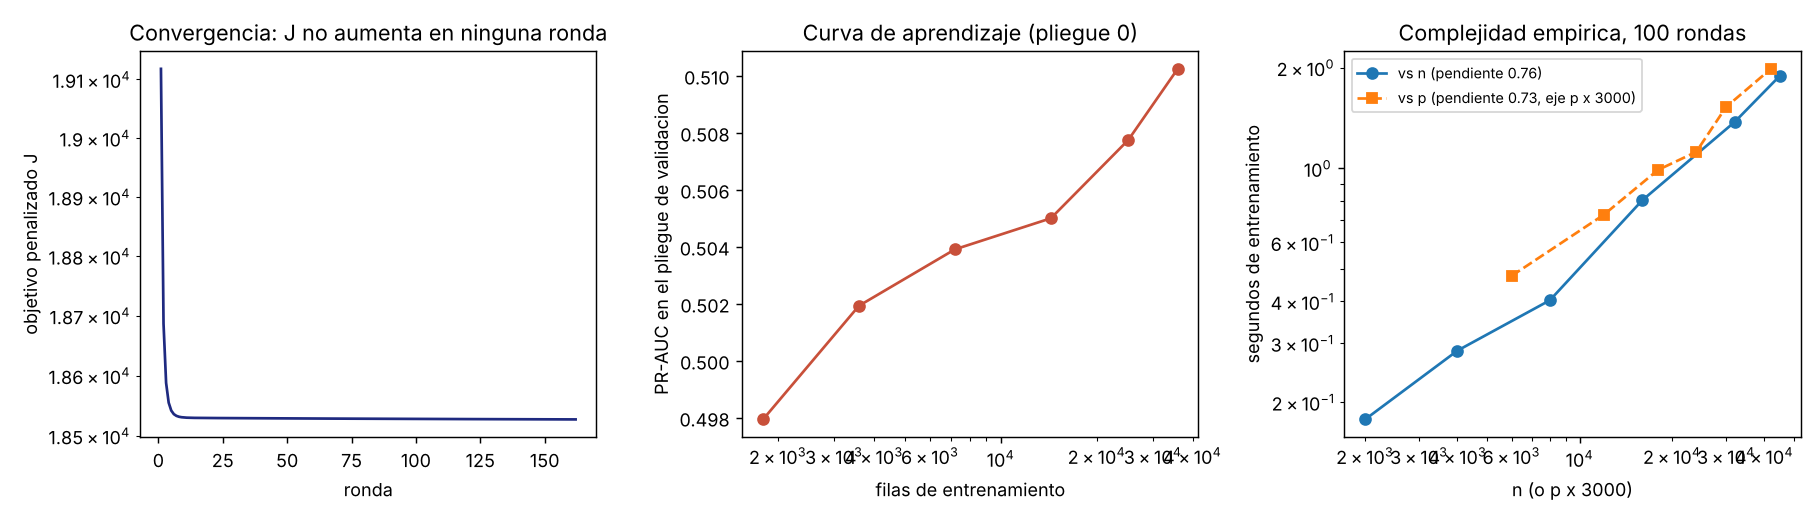

In [2]:
cx = pd.read_csv(RES / "complejidad_original.csv"); ex = json.load(open(RES / "complejidad_original.json"))
display(cx.round(3))
print(f"Exponente empírico del tiempo respecto de n: {ex['exponente_n']:.2f}")
print(f"Exponente empírico del tiempo respecto de p: {ex['exponente_p']:.2f}")
display(Image(str(FIG / "original_convergencia_complejidad.png")))

La figura de la izquierda muestra la convergencia del objetivo $J$ en el modelo final, que baja de forma monótona y se estabiliza en pocas rondas. La del centro es la curva de aprendizaje en el pliegue externo 0, donde la PR-AUC sube de forma sostenida con más filas sin llegar a una meseta clara. La de la derecha es la complejidad empírica.

Los exponentes medidos (0,76 para $n$ y 0,73 para $p$) quedan por debajo del valor teórico de 1 porque cada llamada tiene costos fijos (codificación, creación de arreglos, llamadas a numpy) que pesan mucho con pocas filas o pocas variables. La pendiente entre los dos tamaños más grandes sube hacia 0,9, que es lo esperable cuando el costo lineal domina. En la práctica el modelo se entrena con las 44.903 filas en unos 2 segundos, comparable con la regresión logística y mucho más rápido que el EBM.

## 7.5 Código

El método central es `fit`. Se muestra completo para que se pueda leer junto con el pseudocódigo (el resto de la clase está en `src/original_model.py`).

In [3]:
print(inspect.getsource(AditivoPenalizado.fit))

    def fit(self, X, y):
        """Ajusta el modelo por rondas.

        Parameters
        ----------
        X : DataFrame (n, p) con columnas numericas o categoricas (texto), admite faltantes.
        y : array (n,) con dos clases.
        """
        self._validar_parametros()
        X = self._a_dataframe(X)
        y = np.asarray(y)
        if len(y) != len(X):
            raise ValueError("X e y tienen distinto numero de filas")
        if pd.isna(y).any():
            raise ValueError("y no puede tener faltantes")
        self.classes_ = np.unique(y)
        if len(self.classes_) != 2:
            raise ValueError("Solo se admite clasificacion binaria")
        yb = (y == self.classes_[1]).astype(float)
        n = len(yb)
        self._ajustar_codificador(X)
        cods = {c: self._codificar(X, c) for c in self.columnas_}
        cuentas = {c: np.bincount(cods[c], minlength=self._n_niveles(c)).astype(float) for c in self.columnas_}
        lap = {c: (self._laplaciano(self._n

## 7.6 Pruebas unitarias

Las pruebas están en `tests/test_original_model.py` y se ejecutan con `pytest`. Verifican lo que la guía pide como mínimo y algunas propiedades del algoritmo.

| Prueba | Qué verifica |
|---|---|
| `test_aprende_solucion_conocida` | En datos sintéticos con solución conocida (efectos de la edad, de un factor binario y de un nivel), el modelo recupera la forma verdadera (correlación del logit mayor que 0,97) y el efecto del factor binario |
| `test_la_perdida_no_aumenta_con_ninguna_tasa_ni_penalizacion` | La propiedad de no aumento de $J$ en cada ronda, con tres tasas y con suavizado y sin él |
| `test_reproducible_con_la_misma_semilla` | Dos ajustes con la misma semilla dan probabilidades idénticas |
| `test_entradas_invalidas` | Rechaza tasa o rondas inválidas, penalizaciones negativas, tres clases, largos distintos, faltantes en `y`, columnas ausentes y uso sin ajustar |
| `test_compatible_con_clone_y_parametros` | Compatibilidad con `sklearn.base.clone` |
| `test_faltantes_y_niveles_nuevos_no_rompen` | Maneja faltantes y niveles que no se vieron en el entrenamiento |
| `test_contribuciones_suman_el_logit` | Intercepto más contribuciones es igual al logit, y las curvas están centradas |
| `test_suavizado_reduce_la_rugosidad_de_la_curva` | Con $\kappa$ alto la curva de la edad es menos rugosa que con $\kappa=0$ |

In [4]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_original_model.py"], cwd=RAIZ, capture_output=True, text=True)
print(r.stdout[-600:])

........                                                                 [100%]
8 passed in 1.31s



## 7.7 Hiperparámetros y optimización

Los cuatro hiperparámetros del modelo se optimizan con la búsqueda bayesiana (Optuna con TPE) **dentro** de la validación anidada, con la misma submuestra de 8.000 filas, los mismos 3 pliegues internos y el mismo presupuesto de 12 evaluaciones que los benchmarks.

| Hiperparámetro | Rango | Escala | Qué controla |
|---|---|---|---|
| `n_rondas` | 20 a 300 | entera | Cuántas pasadas se hacen, es el criterio de parada |
| `tasa` ($\eta$) | 0,1 a 1,0 | lineal | Tamaño del paso, con 1 la actualización completa de la cota |
| `lambda_` ($\lambda$) | 1 a 300 | logarítmica | Encogimiento de los valores de cada tabla |
| `kappa` ($\kappa$) | 0,1 a 200 | logarítmica | Suavizado entre niveles vecinos de variables ordenadas |

Los valores finales, buscados sobre el entrenamiento completo, son:

In [5]:
print(json.dumps(json.load(open(RES / "hiperparametros_original.json")), indent=1))

{
 "n_rondas": 162,
 "tasa": 0.6289508325530886,
 "lambda_": 7.27167210455568,
 "kappa": 0.6201075112329003
}


## 7.8 Estudio de ablación

El modelo tiene dos componentes que se pueden retirar por separado, la penalización ridge y la regla propia de suavizado, y además usa el orden de las variables categóricas. Para medir el aporte de cada una se reajusta el modelo en cada uno de los 5 pliegues externos del segundo entregable **con los hiperparámetros que eligió la búsqueda en ese pliegue** y se cambia una sola cosa. No se vuelve a optimizar, así que cada variante parte de la configuración del modelo completo.

In [6]:
ab = pd.read_csv(RES / "ablacion_original.csv", header=[0, 1], index_col=0)
display(ab.style.format(precision=4))

Lectura honesta de la ablación. Quitar el suavizado o el orden de las categóricas **no cambia** la PR-AUC (0,5196 contra 0,5194), y quitar la penalización ridge la baja apenas (0,5187). El único cambio claro es con una sola ronda de entrenamiento, que cae a 0,5133 y empeora la calibración, pero eso solo confirma que el modelo aprende. Lo que sí hace la regla de suavizado es reducir la rugosidad de la curva de la edad en cerca de 7 % (de 3,52 a 3,26 unidades de logit acumuladas entre tramos), un efecto pequeño porque el $\kappa$ elegido por la búsqueda es bajo (0,6) y porque con 45 mil filas los datos ya determinan bien casi todos los niveles.

Es decir, la regla propia es **medible pero no aporta desempeño predictivo** en este problema. Lo reportamos así porque la guía pide mostrar el aporte de cada componente, y la respuesta es que el aporte está en la legibilidad de la curva y no en la métrica.

## 7.9 Interpretabilidad

Cada variable tiene su curva, que es lo que el modelo aprendió y lo que se entrega al usuario del dashboard. La edad reproduce la forma en U que encontramos en el EDA, la depresión tiene un gradiente que crece con la frecuencia de síntomas, la dificultad auditiva separa a quienes tienen alguna dificultad de quienes no tienen, y la educación es protectora de forma gradual.

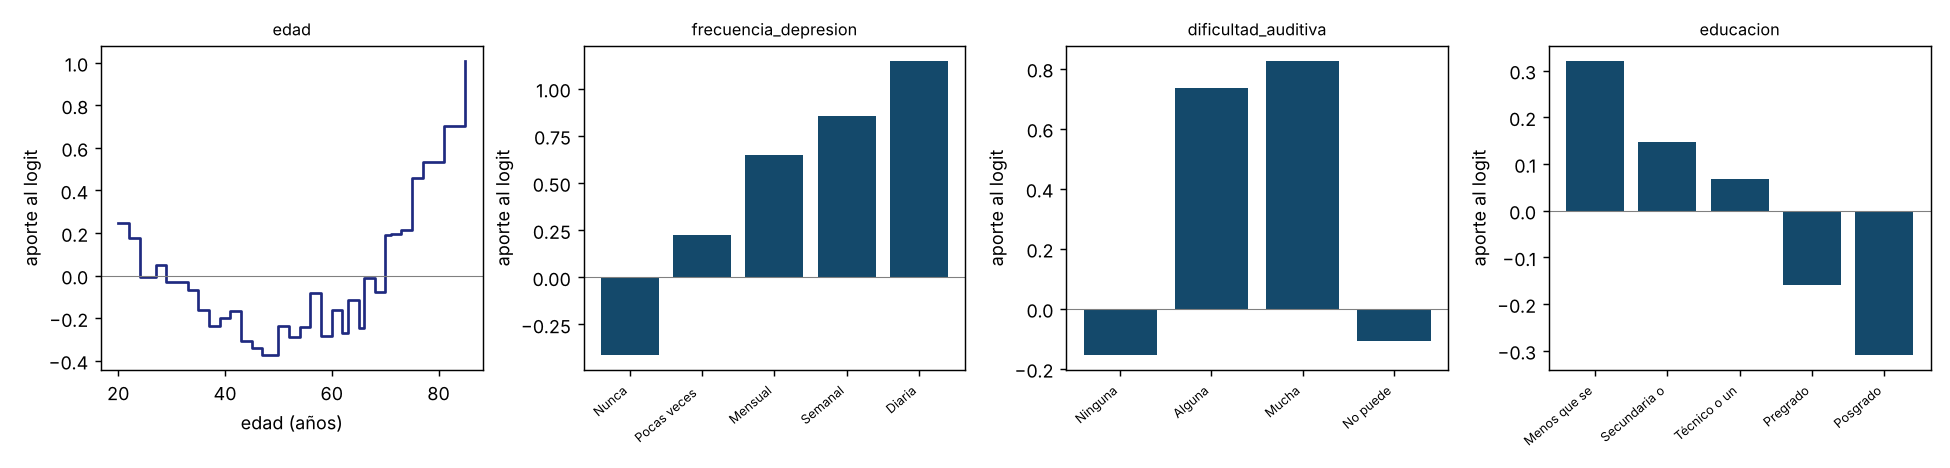

,SHAP_exacto_AditivoPenalizado,SHAP_XGBoost,EBM_importancia
frecuencia_depresion,0.426,0.512,0.426
dificultad_auditiva,0.255,0.278,0.255
depresion_dx,0.244,0.343,0.239
edad,0.240,0.305,0.231
dificultad_visual,0.233,0.255,0.230
educacion,0.166,0.167,0.166
colesterol_alto,0.108,0.092,0.096
tabaquismo,0.073,0.037,0.064


{'vs_SHAP_XGBoost': 0.9296703296703297, 'vs_EBM': 0.9956043956043955}


In [7]:
display(Image(str(FIG / "original_curvas.png")))
imp = pd.read_csv(RES / "importancia_original_vs_referencias.csv", index_col=0)
display(imp.round(3).head(8))
print(json.load(open(RES / "importancia_original_spearman.json")))

La importancia global (media del valor absoluto de la contribución en la prueba) coincide casi por completo con la del EBM (Spearman de 0,996) y mucho con la de SHAP sobre XGBoost (0,93). Las tres variables que más pesan son la frecuencia de síntomas depresivos, la dificultad auditiva y el diagnóstico de depresión o la edad, las mismas que ya identificaron SHAP, los coeficientes de la logística y el EBM en el capítulo 5. La diferencia con XGBoost es de escala, porque SHAP reparte también el efecto de interacciones que el modelo aditivo no tiene.

## 7.10 Desempeño en el conjunto de prueba

Una sola evaluación en la prueba reservada, junto a los finalistas del segundo entregable, con el umbral de 0,245.

In [8]:
display(pd.read_csv(RES / "test_original_vs_finalistas.csv").style.hide(axis="index").format(precision=4))

modelo,PR_AUC,ROC_AUC,Brier,ECE,Recall_u,Precision_u,TN,FP,FN,TP
LogReg,0.5384,0.8038,0.1277,0.0127,0.6381,0.4604,7183,1730,837,1476
SVM,0.5373,0.8035,0.1281,0.0180,0.6252,0.4657,7254,1659,867,1446
XGBoost,0.5406,0.8043,0.1277,0.0181,0.6416,0.4541,7129,1784,829,1484
EBM,0.5436,0.8039,0.1274,0.0097,0.6476,0.4539,7111,1802,815,1498
AditivoPenalizado,0.5402,0.8031,0.1276,0.0121,0.6373,0.4588,7174,1739,839,1474


El modelo propio queda en la misma zona que los demás, con PR-AUC de 0,540 y ROC-AUC de 0,803, y con una calibración muy buena (ECE de 0,012). No supera a ninguno, y el capítulo 8 verifica con pruebas estadísticas si alguna diferencia es significativa.